In [23]:
# IMPORT LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Import Machine Learning and Evaluation tools from scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
# This makes plots look nice in Jupyter
%matplotlib inline



In [32]:
# Load and Prepare the Data

# Load the data
data = pd.read_csv('dynamic_network_slicing_dataset.csv')
print(data.head())

print(data.shape)
print(data.columns)

data.info()

print(data.shape)
print(data.columns)

data.info()
data.describe()

print("Missing values before:", data.isnull().sum().sum())
print("Duplicates before:", data.duplicated().sum())
data = data.drop_duplicates()
data = data.dropna()

# Define the 5 key features from your proposal
# 1. Queue_Length: Packets waiting = early sign of congestion.
# 2. CPU_Utilization_%: Edge server load = compute bottleneck.
# 3. Latency_ms: Delay = direct measure of degradation.
# 4. Traffic_Density: Overall congestion level.
# 5. Vehicle_Speed_kmh: Mobility impact on handover.
features = [
    'Vehicle_Speed_kmh', 
    'Traffic_Density', 
    'Latency_ms', 
    'Queue_Length', 
    'CPU_Utilization_%'
]

# Set input features (X) and target decision label (y)
X = data[features]
y = data['Resource_Allocation_Decision'] # 0 = Maintain, 1 = Increase

# Verify the shapes
print("Features shape (X):", X.shape)
print("Target shape (y):", y.shape)

# Quick check of the first few rows
X.head()


   Slice_ID  Bandwidth_MHz  Latency_ms  Reliability_%  Slice_Priority  \
0         4      17.517242   13.356917      90.767124               1   
1         5      29.001335   10.982152      95.873269               2   
2         3      77.722150   17.678857      91.874542               3   
3         5      14.616446   24.351829      93.576304               3   
4         5      54.328184   15.507210      98.533975               1   

   Vehicle_ID  Vehicle_Speed_kmh  Traffic_Density  Service_Demand_Mbps  \
0        4504          33.387708               61            26.574535   
1        3424          58.538175               13            45.317490   
2        7484          38.215816               42            45.178893   
3        6296          46.476271              115            10.654669   
4        7567          90.638763              138            19.648304   

   MEC_Node_ID  CPU_Utilization_%  Memory_Utilization_MB  Queue_Length  \
0            4          66.798792         

,Vehicle_Speed_kmh,Traffic_Density,Latency_ms,Queue_Length,CPU_Utilization_%
0,33.387708,61,13.356917,13,66.798792
1,58.538175,13,10.982152,8,77.349726
2,38.215816,42,17.678857,47,73.280908
3,46.476271,115,24.351829,33,11.680373
4,90.638763,138,15.507210,43,24.780104


In [26]:
# 3. Data Splitting (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Total Dataset: {len(data)} rows")
print(f"Training Data: {len(X_train)} rows (80%)")
print(f"Testing Data:  {len(X_test)} rows (20%)")

# 4. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Total Dataset: 5000 rows
Training Data: 4000 rows (80%)
Testing Data:  1000 rows (20%)


In [ ]:
# STEP 2: Train the Model

In [ ]:
# 5. Train Model (Random Forest)
# We use Random Forest because it handles your tabular data better than KNN
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train_scaled, y_train)

# 6. Make Predictions
y_pred = model.predict(X_test_scaled)

# 7. Calculate Accuracies
train_acc = accuracy_score(y_train, model.predict(X_train_scaled))
test_acc = accuracy_score(y_test, y_pred)

print("="*40)
print("MODEL PERFORMANCE")
print("="*40)
print(f"Train Accuracy: {train_acc * 100:.2f}%")
print(f"Test Accuracy:  {test_acc * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Maintain (0)', 'Increase (1)']))
joblib.dump(model, 'network_slicing_model.pkl')

MODEL PERFORMANCE
Train Accuracy: 100.00%
Test Accuracy:  100.00%

Classification Report:
              precision    recall  f1-score   support

Maintain (0)       1.00      1.00      1.00       409
Increase (1)       1.00      1.00      1.00       591

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



In [ ]:
# Step 3
from sklearn.metrics import ConfusionMatrixDisplay

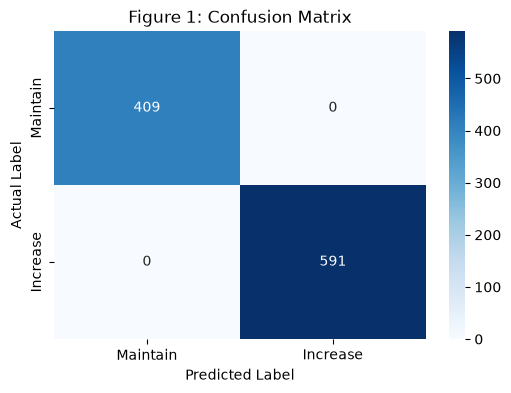

C:\Users\CADT\AppData\Local\Temp\ipykernel_15232\3212522280.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances, y=features, palette="viridis")


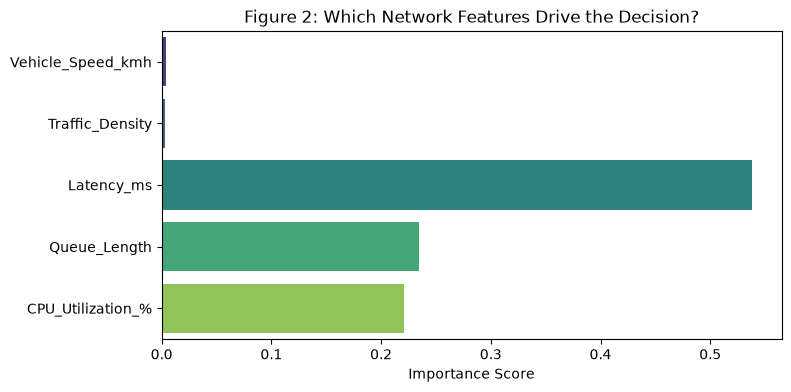

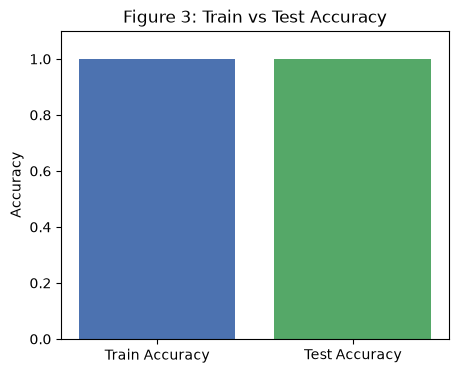

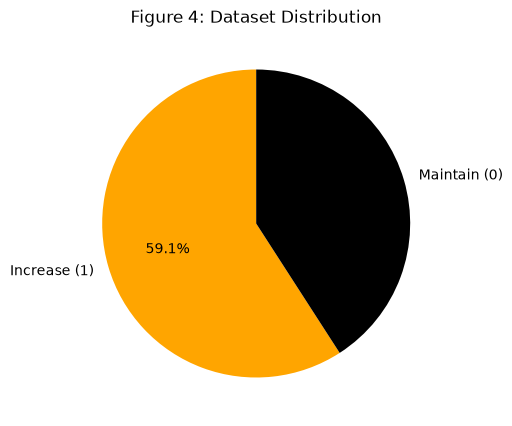

In [27]:
# Figure 1: Confusion Matrix
plt.figure(figsize=(6,4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Maintain', 'Increase'], 
            yticklabels=['Maintain', 'Increase'])
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title("Figure 1: Confusion Matrix")
plt.show()

# Figure 2: Feature Importance
# This answers the lecturer's question: "Why these 5 features?"
plt.figure(figsize=(8, 4))
importances = model.feature_importances_
sns.barplot(x=importances, y=features, palette="viridis")
plt.xlabel("Importance Score")
plt.title("Figure 2: Which Network Features Drive the Decision?")
plt.show()

# Figure 3: Train vs Test Accuracy
# This proves the model is not overfitting
plt.figure(figsize=(5, 4))
plt.bar(["Train Accuracy", "Test Accuracy"], [train_acc, test_acc], color=['#4C72B0', '#55A868'])
plt.ylabel("Accuracy")
plt.ylim(0, 1.1)
plt.title("Figure 3: Train vs Test Accuracy")
plt.show()

# Figure 4: Dataset Distribution (Matches your proposal's pie chart)
plt.figure(figsize=(5, 5))
data['Resource_Allocation_Decision'].value_counts().plot.pie(
    autopct='%1.1f%%', 
    colors=['orange', 'black'], 
    labels=['Increase (1)', 'Maintain (0)'],
    startangle=90
)
plt.title("Figure 4: Dataset Distribution")
plt.ylabel("")
plt.show()